In [1]:
import warnings

import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import pandas as pd

warnings.filterwarnings("ignore")
%config InlineBackend.figure_formats = ["retina"]
plt.rcParams.update({
    "figure.figsize": (9, 4.2),
    "figure.dpi": 90,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.3,
    "axes.titlesize": 13,
    "axes.titleweight": "bold",
    "axes.titlelocation": "left",
    "axes.prop_cycle": plt.cycler(color=["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300",
                                         "#4a3aa7", "#e34948"]),
    "font.size": 11,
    "legend.frameon": False,
})
pd.set_option("display.max_columns", 14)
pd.set_option("display.width", 120)

# Desempleo juvenil

Los filtros de {dd}`geih.serie_indicadores()` calculan los indicadores de cualquier subpoblación. Aquí, los
jóvenes de 15 a 28 años (la definición de la ley de juventud en Colombia), con la serie de empalme hasta
2020 y la principal desde 2022.

In [2]:
import dane_data as dd

def serie(filtros=None, por=None):
    return pd.concat([
        dd.geih.serie_indicadores(range(2010, 2021), empalme=True, filtros=filtros, por=por),
        dd.geih.serie_indicadores(range(2022, 2026), filtros=filtros, por=por),
    ], ignore_index=True)

jovenes = serie({"edad": (15, 28)})
adultos = serie({"edad": (29, 200)})
comparacion = jovenes[["anio", "td"]].merge(adultos[["anio", "td"]], on="anio", suffixes=("_jovenes", "_adultos"))
comparacion.round(1)

,anio,td_jovenes,td_adultos
0,2010,20.5,8.3
1,2011,19.2,7.6
2,2012,18.4,7.3
3,2013,17.1,7.0
4,2014,16.5,6.5
5,2015,15.7,6.6
6,2016,16.7,6.8
7,2017,16.8,6.9
8,2018,17.6,7.1
9,2019,18.5,8.1


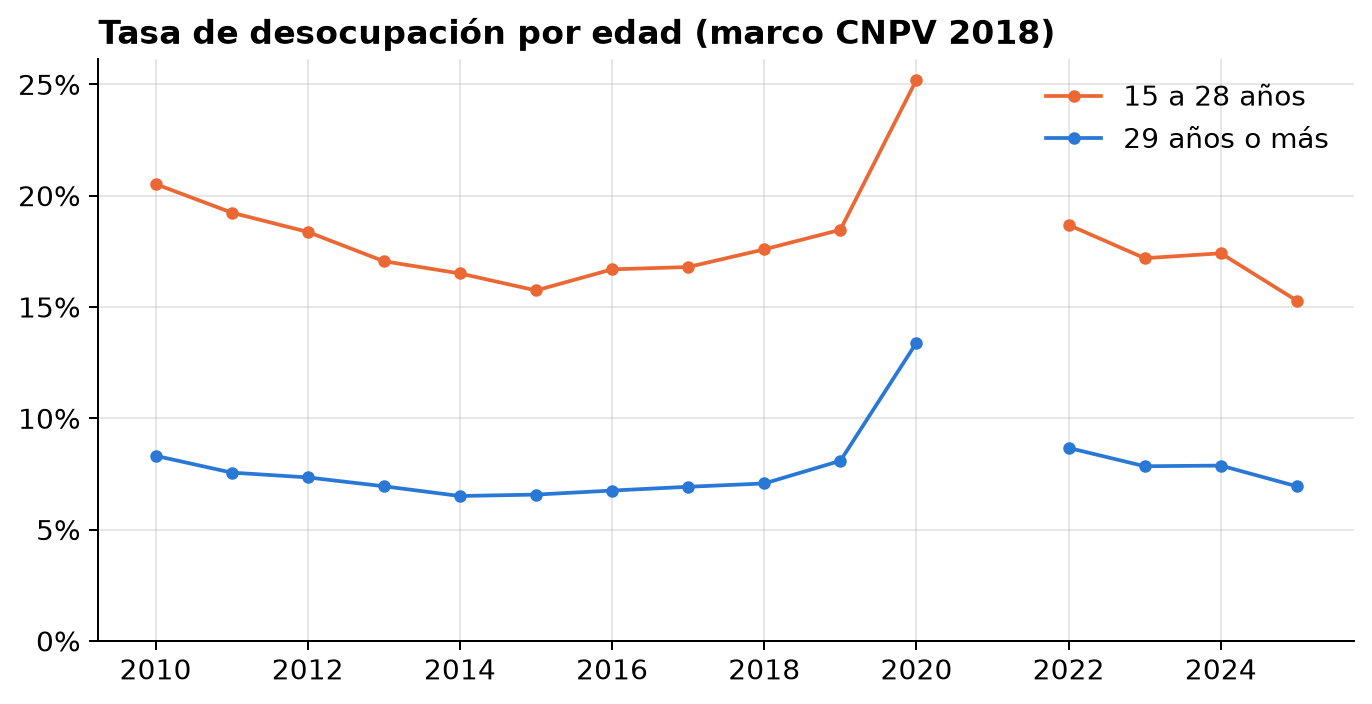

In [3]:
fig, ax = plt.subplots()
for col, etiqueta in [("td_jovenes", "15 a 28 años"), ("td_adultos", "29 años o más")]:
    for tramo in (comparacion[comparacion.anio <= 2020], comparacion[comparacion.anio >= 2022]):
        ax.plot(tramo["anio"], tramo[col], marker="o", ms=4, color="#eb6834" if "jov" in col else "#2a78d6",
                label=etiqueta if tramo["anio"].min() == 2010 else None)
ax.yaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
ax.set_ylim(0, None)
ax.set_title("Tasa de desocupación por edad (marco CNPV 2018)")
ax.legend();

La desocupación de los jóvenes es más del doble de la de los adultos todos los años, y en 2020 subió más
puntos (de 18,5 % a 25,2 %, frente a 8,1 % a 13,4 %).

## Mujeres jóvenes

In [4]:
por_sexo = serie({"edad": (15, 28)}, por="sexo").dropna(subset=["sexo"])
por_sexo.pivot(index="anio", columns="sexo", values="td").round(1)

sexo,Hombre,Mujer
anio,,
2010,16.0,26.7
2011,14.8,25.5
2012,13.9,24.5
2013,13.1,22.4
2014,12.9,21.5
2015,11.8,21.1
2016,12.9,21.8
2017,12.9,22.1
2018,13.6,23.1


## Por nivel educativo, 2025

In [5]:
educ = dd.geih.serie_indicadores(2025, por="nivel_educativo", filtros={"edad": (15, 28)})
educ.dropna(subset=["nivel_educativo"])[["nivel_educativo", "tgp", "td", "n_muestra"]].round(1)

,nivel_educativo,tgp,td,n_muestra
0,Ninguno,27.8,6.9,1622
1,Primaria,66.5,10.3,6276
2,Secundaria,39.4,12.6,28985
3,Media,57.1,15.8,70536
4,Superior,59.6,16.5,67400
